```text
Pipeline
├── 1. Setup & Import
├── 2. Data Loading
├── 3. Target Definition
├── 4. Split
├── 5. Feature Groups
├── 6. Pre-processing Pipelines
├── 7. Model Configuration
├── 8. Feature Selection
├── 9. Full Pipeline
├── 10. Training
├── 11. Prediction & Evaluation
└── 12. Export Pipeline
```

# Pipeline 

#### 1. Setup & Import

In [1]:
# Init work dir

from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
# Standard modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Framework

from src.calibration import FlexibleCalibratedModel
from src.feature_engineering import create_target_def12, GetFeatures
from src.modelling import select_features_gb
from src.preprocessing import input_load, time_split, ReplaceMinusOne

# Dataset specific settings

from src import settings_dataset_unsecured as settings

# ML modules

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import xgboost

# Configuration

from sklearn import set_config; set_config(transform_output="pandas") # set sklearn output: pandas


#### 2. Data Loading

In [3]:
# load input file (DATASET SPECIFIC)

full_dataset = input_load(2016, 2020, column_date=settings.COLUMN_DATE, column_year=settings.COLUMN_YEAR)

#### 3. Target Definition

In [4]:
# CREATE TARGET VARIABLE (DATASET SPECIFIC) STAYS

target_exists = settings.COLUMN_TARGET in full_dataset.columns
if not target_exists:
    full_dataset, dr_summary = create_target_def12(
        full_dataset,
        column_date=settings.COLUMN_DATE,
        column_target_date=settings.COLUMN_TARGET_DATE,
        column_target=settings.COLUMN_TARGET,
        column_year=settings.COLUMN_YEAR,
        verbose=True
    )

LoanDate range:     2016-01-01 00:00:00 2020-12-31 00:00:00
+12 months:         2017-01-01 00:00:00 2021-12-31 00:00:00
DefaultDate range:  2016-04-29 00:00:00 2023-10-13 00:00:00


Year,num_loans,num_defaults,default_rate
2016,6023,1282,0.212851
2017,11109,2447,0.220272
2018,16946,2865,0.169066
2019,28487,4879,0.171271
2020,19959,2294,0.114936


#### 4. Split

In [5]:
# TRAIN/TEST SPLIT

windows = {"train": (2016, 2018), "test":  (2019, 2020)}

splits = time_split(full_dataset, settings.COLUMN_YEAR, windows, settings.COLUMN_TARGET)

X_trai = splits["train"]["X"]
y_trai = splits["train"]["y"]
X_test = splits["test"]["X"]
y_test = splits["test"]["y"]


SPLIT SUMMARY

TRAIN
Years        : 2016 - 2018
Shape (X, y) : (34078, 112), (34078,)

Year distribution
Year
2016     6023
2017    11109
2018    16946
Name: count, dtype: int64

Default rate : 0.1935
------------------------------------------------------------

TEST
Years        : 2019 - 2020
Shape (X, y) : (48446, 112), (48446,)

Year distribution
Year
2019    28487
2020    19959
Name: count, dtype: int64

Default rate : 0.1481
------------------------------------------------------------


#### 5. Feature Groups

In [6]:
# DEFINE NUMERICAL(+ORDINAL)/CATEGORICAL FEATURES

num_cols = [
    feature
    for feature, metadata in settings.FEATURES.items()
    if metadata["type"] in ["numeric", "ordinal"]
    and metadata["pd_eligible"] is True
]

cat_cols = [
    feature
    for feature, metadata in settings.FEATURES.items()
    if metadata["type"] == "categorical"
    and metadata["pd_eligible"] is True
]

# keep the PD eligible features

pd_eligible_features = num_cols + cat_cols
X_trai = X_trai[pd_eligible_features]
X_test = X_test[pd_eligible_features]

#### 6. Pre-processing Pipelines

In [7]:
# assemble pre-processing pipeline

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))    
])

preprocessor = Pipeline([
    ("replace_minus_one", ReplaceMinusOne(verbose=False)),
    ("special_mappings", settings.MAPPING_CLASS(verbose=False)),
    ("columns", ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]))
])

#### 7. Model Configuration

In [8]:
# model configuration

number_of_features = 22

base_model = LogisticRegression(max_iter=10000, random_state=888)
#base_model = xgboost.XGBClassifier(random_state=888, max_depth=2, learning_rate=0.05)

#### 8. Feature Selection

In [9]:
# select n top features from GB importance

X_trai_preprocessed = preprocessor.fit_transform(X_trai)

selected_features, feature_importance = select_features_gb(y_trai, X_trai_preprocessed, number_of_features)
feature_importance

num__NewCreditCustomer                    0.098069
num__AppliedAmount                        0.092383
num__LiabilitiesTotal                     0.063482
cat__Education_5.0                        0.062147
num__Age                                  0.059193
num__CreditScoreEeMini                    0.053011
num__PreviousRepaymentsBeforeLoan         0.051835
cat__HomeOwnershipType_8.0                0.045295
num__LoanDuration                         0.044981
cat__Education_2.0                        0.035799
cat__LanguageCode_3.0                     0.035670
num__MonthlyPayment                       0.035228
num__ExistingLiabilities                  0.034818
num__WorkExperience                       0.029425
num__Amount                               0.027579
num__AmountOfPreviousLoansBeforeLoan      0.024495
num__EmploymentDurationCurrentEmployer    0.022193
num__FreeCash                             0.022011
num__ApplicationSignedHour                0.020595
num__IncomeFromPrincipalEmploye

#### 9. Full Pipeline

In [10]:
# assemble the end-to-end modelling pipeline (EXPERIMENT SPECIFIC)

pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("scaler", StandardScaler()),
    ("feature_selection", GetFeatures(selected_features)),
    ############ calibration = None  ############
    # ("model", base_model)
    ############ calibration = shift ############
    ("model", FlexibleCalibratedModel(
        base_model=base_model,
        calibration="shift", # "shift", "sigmoid", "isotonic", None
        #shift=-0.28456611461537196 # when base model is GB
        shift=-0.38330530029264454  # when base model is LR
    ))
])

#### 10. Training

In [11]:
# training

pipeline.fit(X_trai, y_trai);

#### 11. Prediction & Evaluation

##### Validation (old model replication)

In [12]:
# TEST 1: pipeline features

pipe_features = pipeline.named_steps["feature_selection"].selected_features
print(len(pipe_features))
print(pipe_features)

22
['num__NewCreditCustomer', 'num__AppliedAmount', 'num__LiabilitiesTotal', 'cat__Education_5.0', 'num__Age', 'num__CreditScoreEeMini', 'num__PreviousRepaymentsBeforeLoan', 'cat__HomeOwnershipType_8.0', 'num__LoanDuration', 'cat__Education_2.0', 'cat__LanguageCode_3.0', 'num__MonthlyPayment', 'num__ExistingLiabilities', 'num__WorkExperience', 'num__Amount', 'num__AmountOfPreviousLoansBeforeLoan', 'num__EmploymentDurationCurrentEmployer', 'num__FreeCash', 'num__ApplicationSignedHour', 'num__IncomeFromPrincipalEmployer', 'cat__VerificationType_4.0', 'cat__HomeOwnershipType_3.0']


##### Prediction

/Users/konstantinoskazanas/Downloads/DATA SCIENCE/MLenv/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


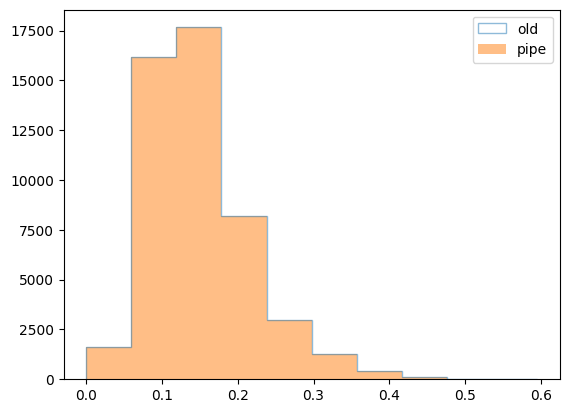

In [13]:
# prediction
y_pred_trai_pipe = pipeline.predict_proba(X_trai)[:,1]
y_pred_test_pipe = pipeline.predict_proba(X_test)[:,1]

# load old model PDs
y_pred_test_old = pd.read_pickle("../archive/old_predictions/y_pred_test_old.pkl")

# compare pipe PDs / old PDs
plt.hist(y_pred_test_old , alpha=0.5, label="old", histtype="step")
plt.hist(y_pred_test_pipe, alpha=0.5, label="pipe")
plt.legend()
plt.show()


In [14]:
print(list(enumerate(cat_cols)))

[(0, 'Education'), (1, 'EmploymentStatus'), (2, 'Gender'), (3, 'HomeOwnershipType'), (4, 'LanguageCode'), (5, 'MaritalStatus'), (6, 'OccupationArea'), (7, 'UseOfLoan'), (8, 'VerificationType')]


In [15]:
train_values = set(X_trai["LanguageCode"].dropna().unique())
test_values = set(X_test["LanguageCode"].dropna().unique())

print("Train:", sorted(train_values))
print("Test :", sorted(test_values))
print("Unknown in test:", sorted(test_values - train_values))

Train: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Test : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(9)]
Unknown in test: [np.int64(6), np.int64(9)]


Known train/test category difference: LanguageCode values 6 and 9 occur in test but not train; current OneHotEncoder(handle_unknown="ignore") maps them to all-zero encoded categories.

#### 12. Export Pipeline

In [16]:
## export trained pipeline (NOTEBOOK SHOULD PROVIDE THE NAME OF THE PKL ACCORDING TO EXPERIMENT CHOICES)

import joblib
joblib.dump(pipeline, "../models/PIPELINE_PD_ver_XXX_LR_cal_XXXX.pkl")

## pipeline names:

# PIPELINE_PD_ver_012.pkl             :  model version 1.0 (LR) calibration shift test (standard pipeline)
# PIPELINE_PD_ver_012_LR.pkl          :  model version 1.0 (LR) calibration shift test 
# PIPELINE_PD_ver_012_LR_cal_none.pkl :  model version 1.0 (LR) calibration none
# PIPELINE_PD_ver_012_GB.pkl          :  model version 1.0 (GB) calibration shift test

['../models/PIPELINE_PD_ver_XXX_LR_cal_XXXX.pkl']